In [1]:
import autograd.numpy as anp
import pymanopt
from pymanopt.manifolds import Sphere, Product
import numpy as np
from pymanopt.tools import diagnostics
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from autograd import value_and_grad

In [2]:
n = 2
manifold_1 = Sphere(n)
manifold_2 = Sphere(n)
manifold = Product([manifold_1, manifold_2])

In [59]:
@pymanopt.function.autograd(manifold)
def cost(point):
    return anp.sin(point[0]) * anp.sin(point[1])

In [60]:
x = np.linspace(0, 2*np.pi, 100)
y = np.linspace(0, 2*np.pi, 100)
X, Y = np.meshgrid(x, y)
Z = cost([X,Y])

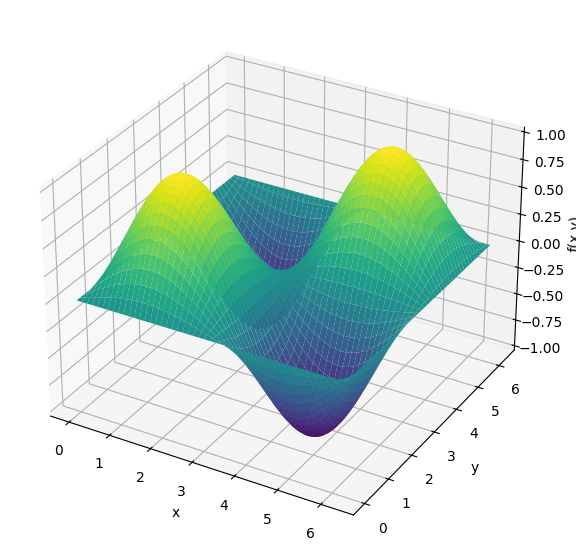

In [61]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X, Y, Z, cmap='viridis')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f(x,y)')
plt.show()

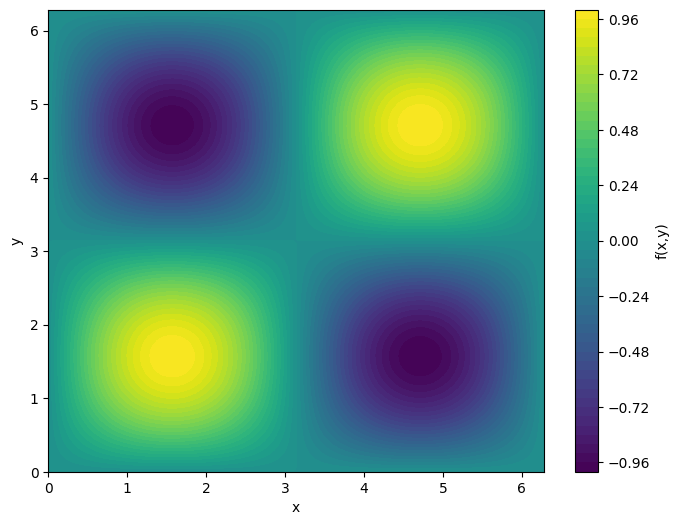

In [62]:
plt.figure(figsize=(8, 6))
plt.contourf(X, Y, Z, levels=50, cmap='viridis')
plt.colorbar(label='f(x,y)')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [66]:
n_starts = 20
fun_jac = value_and_grad(cost)
result = []
histories = []
bounds = [(0, 2*np.pi)]*2
for i in range(n_starts):
    history = []
    x0 = np.random.uniform(0.2, 2*np.pi - 0.2, size=2)
    # x0 = anp.array([0, 4*np.pi / 3])
    def callback(xk):
        f_val, grad = fun_jac(xk)
        history.append({
            "x": xk.copy(),
            "f": f_val,
            "grad_norm": np.linalg.norm(grad)
        })
    r = minimize(fun_jac, x0, jac=True, bounds=bounds, method="L-BFGS-B", callback=callback)
    histories.append(history)
    print(f"Run {i}: optimal point: {r.x} | minimum value: {r.fun}")

Run 0: optimal point: [4.71238618 1.57079606] | minimum value: -0.9999999999960424
Run 1: optimal point: [6.28318531 4.75157701] | minimum value: 2.447413146888471e-16
Run 2: optimal point: [4.71238782 1.57079534] | minimum value: -0.9999999999988365
Run 3: optimal point: [1.57079638 4.71238909] | minimum value: -0.9999999999999927
Run 4: optimal point: [0.90706366 0.        ] | minimum value: 0.0
Run 5: optimal point: [4.71238685 1.57079411] | minimum value: -0.9999999999952706
Run 6: optimal point: [1.57079622 4.7123904 ] | minimum value: -0.9999999999989921
Run 7: optimal point: [5.41487349 6.28318531] | minimum value: 1.8693970390169816e-16
Run 8: optimal point: [4.71238898 1.57079633] | minimum value: -1.0
Run 9: optimal point: [1.3169678 0.       ] | minimum value: 0.0
Run 10: optimal point: [1.57079614 4.71238821] | minimum value: -0.9999999999996827
Run 11: optimal point: [1.57080005 4.71238811] | minimum value: -0.9999999999926943
Run 12: optimal point: [1.57079633 4.71238898]

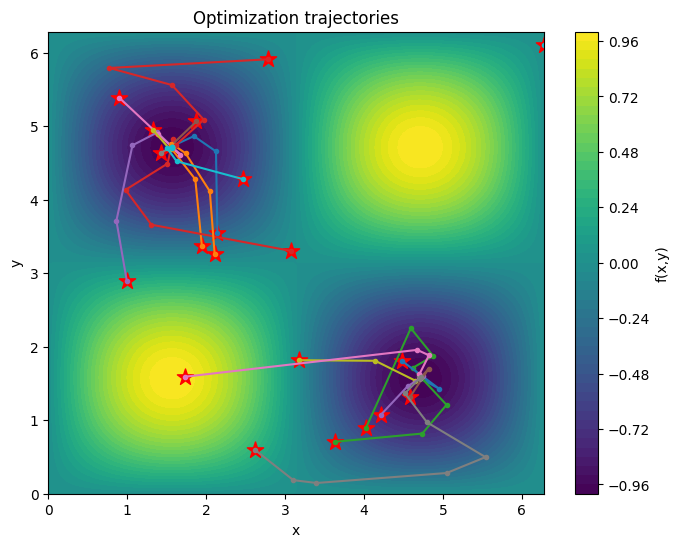

In [54]:
plt.figure(figsize=(8, 6))
plt.contourf(X, Y, Z, levels=50, cmap='viridis')
plt.colorbar(label='f(x,y)')
for i, history in enumerate(histories):
    points = np.array([h["x"] for h in history])

    # Optimization trajectory
    plt.plot(points[:, 0], points[:, 1], '-o', markersize=3)

    # Initial point
    plt.scatter(points[0, 0], points[0, 1],
                marker='*', color='red', s=150,
                label='Initial point' if i == 0 else None)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Optimization trajectories")
plt.show()

In [52]:
@pymanopt.function.autograd(manifold)
def riemannian_cost(point_1, point_2):
    return point_1[1] * point_2[1]

problem = pymanopt.Problem(manifold, riemannian_cost)

for i in range(n_starts): 
    X0 = problem.manifold.random_point()
    optimizer = pymanopt.optimizers.SteepestDescent(verbosity=0)
    result = optimizer.run(problem, initial_point=X0)
    print(f"Run {i+1}: {result.point}, {result.cost} ")

Run 1: [array([-2.0146008e-07, -1.0000000e+00]), array([4.85571301e-07, 1.00000000e+00])], -0.9999999999998619 
Run 2: [array([ 8.22072455e-08, -1.00000000e+00]), array([7.90490367e-08, 1.00000000e+00])], -0.9999999999999936 
Run 3: [array([-2.03070796e-09, -1.00000000e+00]), array([2.14770902e-08, 1.00000000e+00])], -0.9999999999999998 
Run 4: [array([-3.80771525e-07, -1.00000000e+00]), array([6.59781718e-07, 1.00000000e+00])], -0.99999999999971 
Run 5: [array([5.53948285e-08, 1.00000000e+00]), array([-5.61954214e-08, -1.00000000e+00])], -0.9999999999999969 
Run 6: [array([-6.10778052e-08, -1.00000000e+00]), array([-8.14766677e-08,  1.00000000e+00])], -0.9999999999999949 
Run 7: [array([3.36715712e-08, 1.00000000e+00]), array([-1.98959758e-09, -1.00000000e+00])], -0.9999999999999996 
Run 8: [array([ 8.29467889e-08, -1.00000000e+00]), array([-7.80962558e-08,  1.00000000e+00])], -0.9999999999999938 
Run 9: [array([5.64897507e-08, 1.00000000e+00]), array([-5.32872389e-08, -1.00000000e+00